IS_SOLD CLASSIFICATION - V1 (BASELINE)

✅ Data Loaded: (250, 8)

Features: 11
Samples: 250

Target Distribution:
Is_Sold
0    151
1     99
Name: count, dtype: int64

Train: (200, 11), Test: (50, 11)

MODEL 1: Random Forest
Accuracy: 0.5800
              precision    recall  f1-score   support

    Not Sold       0.63      0.73      0.68        30
        Sold       0.47      0.35      0.40        20

    accuracy                           0.58        50
   macro avg       0.55      0.54      0.54        50
weighted avg       0.56      0.58      0.57        50


MODEL 2: XGBoost
Accuracy: 0.5000
              precision    recall  f1-score   support

    Not Sold       0.57      0.70      0.63        30
        Sold       0.31      0.20      0.24        20

    accuracy                           0.50        50
   macro avg       0.44      0.45      0.43        50
weighted avg       0.46      0.50      0.47        50



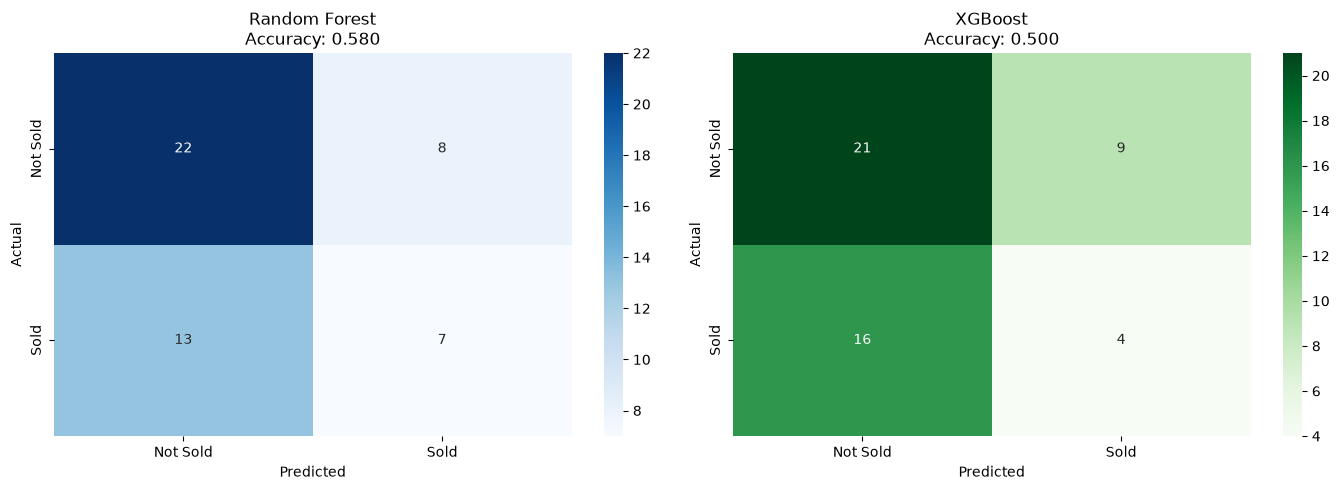

✅ is_sold_confusion_matrix_v1.png saved
✅ is_sold_classifier_v1.pkl saved (Random Forest)

V1 - DONE ✅


In [ ]:
# File: 04_is_sold_classification.ipynb
# Version: V1 - Baseline
# Author: Youssef
# ------------------------------------------------

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("IS_SOLD CLASSIFICATION - V1 (BASELINE)")
print("=" * 60)

# ------------------------------------------------
# 1. Load Data

df = pd.read_csv('../../1_Data/cleaned_data.csv')    # ← عدّلنا الـ Path
df = df.drop('Property_ID', axis=1)
df['Is_Sold'] = df['Is_Sold'].map({'Yes': 1, 'No': 0})

print(f"\n Data Loaded: {df.shape}")

# ------------------------------------------------
# 2. Simple Encoding

df_encoded = pd.get_dummies(df, columns=['Location', 'Property_Type'], drop_first=True)

# ------------------------------------------------
# 3. Features & Target

X = df_encoded.drop(['Is_Sold', 'Price_EGP'], axis=1)
y = df_encoded['Is_Sold']

print(f"\nFeatures: {X.shape[1]}")
print(f"Samples: {X.shape[0]}")
print(f"\nTarget Distribution:")
print(y.value_counts())

# ------------------------------------------------
# 4. Train/Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\nTrain: {X_train.shape}, Test: {X_test.shape}")

# ------------------------------------------------
# 5. Random Forest

print("\n" + "=" * 60)
print("MODEL 1: Random Forest")
print("=" * 60)

rf_clf = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10)
rf_clf.fit(X_train, y_train)
rf_pred = rf_clf.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)

print(f"Accuracy: {rf_acc:.4f}")
print(classification_report(y_test, rf_pred, target_names=['Not Sold', 'Sold']))

# ------------------------------------------------
# 6. XGBoost

print("\n" + "=" * 60)
print("MODEL 2: XGBoost")
print("=" * 60)

xgb_clf = XGBClassifier(n_estimators=100, random_state=42, max_depth=5, eval_metric='logloss')
xgb_clf.fit(X_train, y_train)
xgb_pred = xgb_clf.predict(X_test)
xgb_acc = accuracy_score(y_test, xgb_pred)

print(f"Accuracy: {xgb_acc:.4f}")
print(classification_report(y_test, xgb_pred, target_names=['Not Sold', 'Sold']))

# ------------------------------------------------
# 7. Confusion Matrix

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(confusion_matrix(y_test, rf_pred), annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Not Sold', 'Sold'], yticklabels=['Not Sold', 'Sold'])
axes[0].set_title(f'Random Forest\nAccuracy: {rf_acc:.3f}')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_test, xgb_pred), annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Not Sold', 'Sold'], yticklabels=['Not Sold', 'Sold'])
axes[1].set_title(f'XGBoost\nAccuracy: {xgb_acc:.3f}')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.savefig('is_sold_confusion_matrix_v1.png', dpi=150, bbox_inches='tight')
plt.show()
print("is_sold_confusion_matrix_v1.png saved")

# ------------------------------------------------
# 8. Save Best

if rf_acc >= xgb_acc:
    joblib.dump(rf_clf, 'is_sold_classifier_v1.pkl')
    print(f" is_sold_classifier_v1.pkl saved (Random Forest)")
else:
    joblib.dump(xgb_clf, 'is_sold_classifier_v1.pkl')
    print(f" is_sold_classifier_v1.pkl saved (XGBoost)")

print("\n" + "=" * 60)
print("V1 - DONE WITH IS_SOLD CLASSIFICATION")
print("=" * 60)